In [43]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.compose import  ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import  StandardScaler , TargetEncoder , FunctionTransformer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_absolute_percentage_error,
    root_mean_squared_error,
    mean_squared_error,
)

In [44]:
import kagglehub
import pandas as pd
import os

# 1. Download the dataset folder path
folder_path = kagglehub.dataset_download("yasserh/uber-fares-dataset")

# 2. Point directly to the CSV file inside that folder
csv_path = os.path.join(folder_path, "uber.csv")

# 3. Load it normally with Pandas
data = pd.read_csv(csv_path)

# Let's see if it loaded perfectly
print(data.head())

Using Colab cache for faster access to the 'uber-fares-dataset' dataset.
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325               

In [45]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [46]:
data.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [47]:
data.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [48]:
data = data.drop("Unnamed: 0", axis=1)

In [49]:
data.duplicated().sum()

np.int64(0)

**there is no duplicates to remove**

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ #

## new columns exatracted !!

In [50]:
!pip install h3
#! most of the columns here are taken from ai cause i didn't know the idea on how to get them !!
from equation import equations
from sklearn.decomposition import PCA
import h3

equat = equations()
data['distance_travelled'] = equat.haversine_distance(data['pickup_latitude'] , data['pickup_longitude'] ,data['dropoff_latitude'] , data['dropoff_longitude'] )
############################################################################################################
data['bearing'] = equat.calculate_bearing(data['pickup_latitude'] , data['pickup_longitude'] ,data['dropoff_latitude'] , data['dropoff_longitude'])
############################################################################################################
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'] , format = '%Y-%m-%d %H:%M:%S UTC')
data['year'] = data['pickup_datetime'].dt.year
data['month'] = data['pickup_datetime'].dt.month
data['day'] = data['pickup_datetime'].dt.day
data['hour'] = data['pickup_datetime'].dt.hour
############################################################################################################
# Combine both into a single series to find the true global center
all_lats = pd.concat([data["pickup_latitude"], data["dropoff_latitude"]])
all_lons = pd.concat([data["pickup_longitude"], data["dropoff_longitude"]])
dataset_center_lat = all_lats.median()
dataset_center_lon = all_lons.median()
data["pickup_to_center_distance"] = equat.haversine_distance(data["pickup_latitude"], data["pickup_longitude"], dataset_center_lat, dataset_center_lon)
data["dropoff_to_center_distance"] = equat.haversine_distance(data["dropoff_latitude"], data["dropoff_longitude"], dataset_center_lat, dataset_center_lon)
############################################################################################################
# Returns True (1) if day is Saturday (5) or Sunday (6), otherwise False (0)
data['weekend'] = data['pickup_datetime'].dt.dayofweek.isin([5, 6]).astype(int)
############################################################################################################
day_of_week = data['pickup_datetime'].dt.dayofweek
is_weekday = day_of_week < 5
is_rush_hour = data['hour'].isin([7, 8, 9, 16, 17, 18]).astype(int)
data['rushhour'] = (is_rush_hour & is_weekday).astype(int)
############################################################################################################
data["pickup_hex_8"] = [h3.latlng_to_cell(lat, lon, 8) for lat, lon in zip(data["pickup_latitude"], data["pickup_longitude"])
]############################################################################################################
theta = np.pi / 4
data["pickup_lat_rot45"] = data["pickup_longitude"] * np.sin(theta) + data["pickup_latitude"] * np.cos(theta)
data["pickup_lon_rot45"] = data["pickup_longitude"] * np.cos(theta) - data["pickup_latitude"] * np.sin(theta)
############################################################################################################
pca = PCA(n_components=2)
# Fit on pickup coordinates and transform them
pickup_pca = pca.fit_transform(data[["pickup_latitude", "pickup_longitude"]])
data["pickup_pca1"] = pickup_pca[:, 0]
data["pickup_pca2"] = pickup_pca[:, 1]
############################################################################################################
# If the delta is tiny, they stayed in the immediate neighborhood cluster
data["is_local_trip"] = ((abs(data["pickup_latitude"] - data["dropoff_latitude"]) < 0.01)& (abs(data["pickup_longitude"] - data["dropoff_longitude"]) < 0.01)).astype(int)

### now to explain what i have done in the recent code blocks  :

***distance_travelled : Purpose: Calculates the straight-line (as the crow flies) distance between the start and end of the ride using the Earth's curvature.                                                                                  Model Impact: This is your heavy hitter. It will almost certainly have the highest Feature Importance in your model. Ride-sharing fares scale monotonically with distance. Giving the model this pre-calculated value saves it from having to do complex non-linear trigonometry to figure out that "coordinates far apart = expensive ride***

***bearing : Purpose: Measures the compass direction of the trip (e.g., 0 is North , 90 is East).Model Impact: Real-world traffic and demand are heavily directional. For example, traveling East into a city center at 8:00 AM behaves differently than traveling West away from it. Tree-based models use bearing to map asymmetrical traffic pricing patterns.***

***year , month , doy , hour : purpose: this is the date time of the tripe . Model Impact: by this we add extra factors like the season of the tripe where sunny and rainy days differ the ride fare***

***pickup_to_center_distance & dropoff_to_center_distance : Purpose: Measures how far the passenger is from the absolute heart (median center) of the dataset's footprint.Model Impact: City centers are hotspots for traffic delays, high demand, and toll boundaries. A 3-mile trip deep inside downtown takes much longer and costs more than a 3-mile trip out in the rural suburbs. This feature gives your model a spatial anchor to understand localized economic density.***

***weekend & rushhour : Purpose: Explicitly flags high-traffic conditions based on the calendar.Model Impact: While a tree model could technically figure out that traffic is bad when dayofweek < 5 AND hour == 8, you are saving it massive depth and computational energy by handing it these 1 and 0 flags directly. It allows the model to instantly isolate premium surge-pricing windows.***

***pickup_hex_8 : Purpose: Converts raw decimal coordinates into a standardized string ID representing a ~700-meter hexagon on the ground.Model Impact: Raw latitudes and longitudes are continuous floating numbers, which decision trees struggle to group effectively. By turning coordinates into a categorical "Hexagon ID", the model can cleanly group data into micro-neighborhoods. It can easily learn: "If pickup_hex_8 == '882a10...', apply a $5 surge premium."***

***pickup_lat_rot45 & pickup_lon_rot45 : Purpose: Rotates your coordinate grid by 45.Model Impact: Decision trees can only split data with straight horizontal (latitude > X) or vertical (longitude > Y) lines. If a city’s main highway or coastline runs diagonally, a tree needs dozens of messy "stair-step" splits to isolate it. Rotating the coordinates allows the tree to capture diagonal geographic boundaries with a single, clean split.***

***pickup_pca1 & pickup_pca2 : Purpose: Principal Component Analysis finds the axes of maximum variance in your spatial data. If your city is a long island (like Manhattan), pca1 will align perfectly with the length of the island, and pca2 with its width.Model Impact: It strips out coordinate noise and realigns the spatial grid to match the actual footprint of human activity in that city, making it much easier for linear models and trees to weigh spatial spreads.***

***is_local_trip : Purpose: A binary flag (1 or 0) indicating if the pickup and dropoff coordinates are in the exact same tiny geographic radius.Model Impact: Helps your model immediately identify short, hyper-local neighborhood hops. These trips often hit the automated "Minimum Base Fare" threshold of the ride-sharing platform, allowing the model to override general distance calculations and assign the flat base price.***

In [51]:
#! i noticed that the key column is exact same as the pickup_daytime column but was a random decimal points at the end of it . so it is like an id which will not give me any info !
data = data.drop(['key' , 'pickup_datetime'] , axis = 1)

In [52]:
no_below_zero = ["fare_amount", "passenger_count", "distance_travelled", "pickup_to_center_distance", "dropoff_to_center_distance"]
data = data[(data[no_below_zero] >= 0).all(axis=1)]
data

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_travelled,bearing,year,month,...,pickup_to_center_distance,dropoff_to_center_distance,weekend,rushhour,pickup_hex_8,pickup_lat_rot45,pickup_lon_rot45,pickup_pca1,pickup_pca2,is_local_trip
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,1.683323,179.124609,2015,5,...,2.256403,3.640444,0,0,882a100d27fffff,-23.519406,-81.132139,-1.673964,-0.095456,0
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2.457590,359.302804,2009,7,...,2.955197,1.186321,0,0,882a1072c9fffff,-23.522706,-81.121114,-1.663978,-0.101176,0
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,5.036377,45.254124,2009,8,...,2.426670,2.698563,0,0,882a10721bfffff,-23.521393,-81.137542,-1.679678,-0.096162,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,1.661683,33.192997,2009,6,...,4.249857,5.773670,0,1,882a100883fffff,-23.465537,-81.152501,-1.681545,-0.038368,0
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,4.475450,295.254931,2014,8,...,4.815087,1.152196,0,1,882a100d51fffff,-23.462466,-81.083304,-1.613462,-0.051111,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,3.0,-73.987042,40.739367,-73.986525,40.740297,1,0.112210,22.840918,2012,10,...,1.578098,1.466191,1,0,882a100d21fffff,-23.509656,-81.123822,-1.663648,-0.087853,1
199996,7.5,-73.984722,40.736837,-74.006672,40.739620,1,1.875050,279.506634,2014,3,...,1.802728,2.611862,0,0,882a100d23fffff,-23.509805,-81.120392,-1.660342,-0.088777,0
199997,30.9,-73.986017,40.756487,-73.858957,40.692588,2,12.850319,123.526348,2009,6,...,0.587760,12.273150,0,0,882a100d67fffff,-23.496826,-81.135203,-1.671814,-0.072771,0
199998,14.5,-73.997124,40.725452,-73.983215,40.695415,1,3.539715,160.654710,2015,5,...,3.330516,6.383989,0,0,882a1072c9fffff,-23.526624,-81.121112,-1.664867,-0.104993,0


In [53]:
x = data.drop('fare_amount' , axis = 1 )
y = data['fare_amount']
x_train , x_test , y_train , y_test = train_test_split(x ,y , test_size= 0.2 , random_state=42)

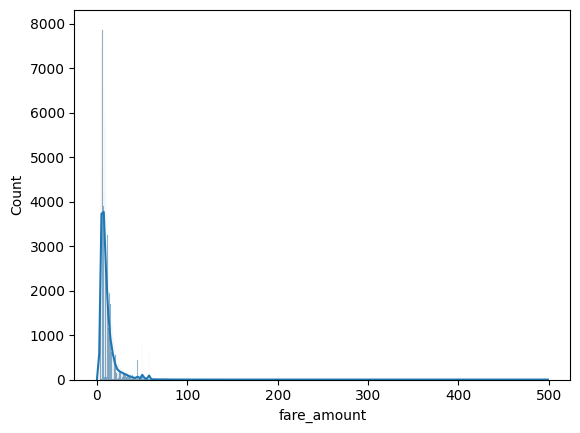

In [54]:
sns.histplot(y_train , kde=True)
plt.show()

## the data is right skewed !!

<Axes: xlabel='distance_travelled', ylabel='fare_amount'>

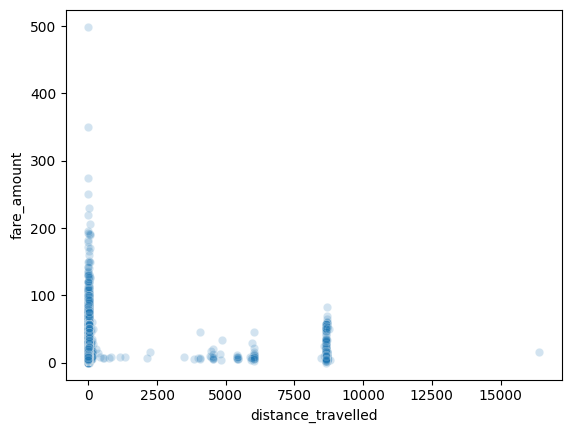

In [55]:
sns.scatterplot(x = x_train['distance_travelled'] , y = y_train , alpha = 0.2)

### so much outliers !!

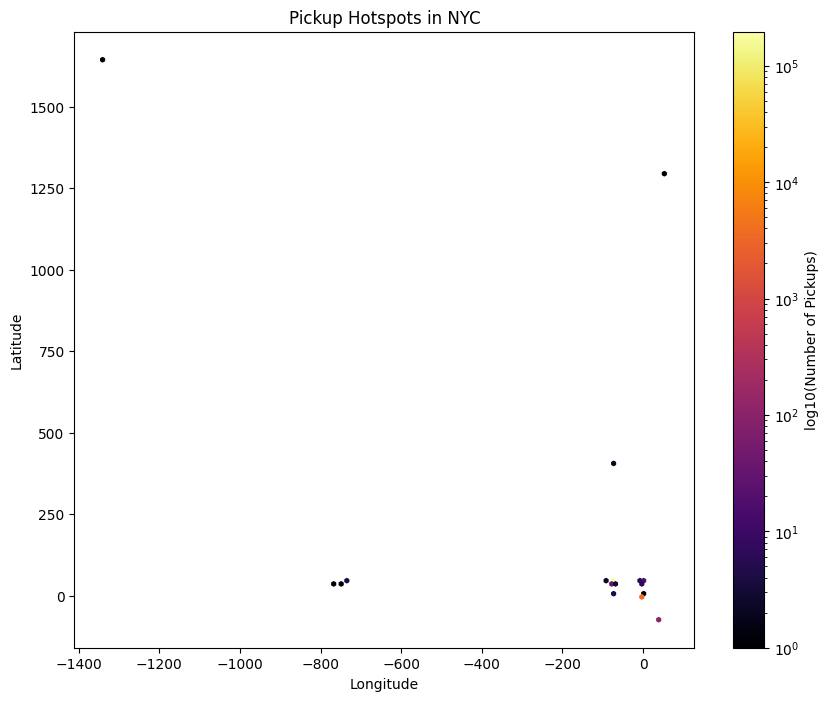

In [56]:
# Hexbin plot: brighter colors = more pickups
# gridsize: controls the size of the hexagons (higher = finer detail)
# bins='log': uses a logarithmic scale for color so huge hotspots don't drown out smaller ones
plt.figure(figsize=(10, 8))
plt.hexbin(data['pickup_longitude'], data['pickup_latitude'],
           gridsize=150, cmap='inferno', bins='log', mincnt=1)

plt.colorbar(label='log10(Number of Pickups)')
plt.title('Pickup Hotspots in NYC')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

It appears there are extreme outliers in the geographical coordinates, which makes the hexbin plot very sparse. Let's filter the data to the typical geographical boundaries of New York City to get a more meaningful visualization.

Original data points: 199982
Filtered NYC data points: 195465


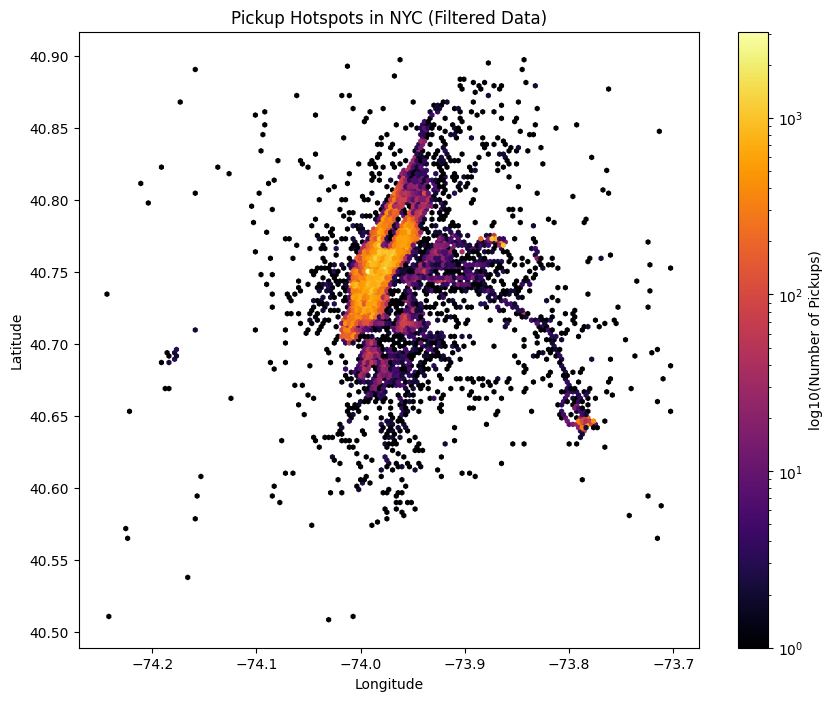

In [57]:
nyc_min_lon, nyc_max_lon = -74.25, -73.7
nyc_min_lat, nyc_max_lat = 40.5, 40.9

# Filter the data for NYC coordinates
data_nyc = data[
    (data['pickup_longitude'] >= nyc_min_lon) & (data['pickup_longitude'] <= nyc_max_lon) &
    (data['pickup_latitude'] >= nyc_min_lat) & (data['pickup_latitude'] <= nyc_max_lat) &
    (data['dropoff_longitude'] >= nyc_min_lon) & (data['dropoff_longitude'] <= nyc_max_lon) &
    (data['dropoff_latitude'] >= nyc_min_lat) & (data['dropoff_latitude'] <= nyc_max_lat)
].copy()

print(f"Original data points: {len(data)}")
print(f"Filtered NYC data points: {len(data_nyc)}")

# Regenerate the hexbin plot with filtered data
plt.figure(figsize=(10, 8))
plt.hexbin(data_nyc['pickup_longitude'], data_nyc['pickup_latitude'],
           gridsize=150, cmap='inferno', bins='log', mincnt=1)

plt.colorbar(label='log10(Number of Pickups)')
plt.title('Pickup Hotspots in NYC (Filtered Data)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [58]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 159985 entries, 15044 to 121967
Data columns (total 21 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   pickup_longitude            159985 non-null  float64
 1   pickup_latitude             159985 non-null  float64
 2   dropoff_longitude           159985 non-null  float64
 3   dropoff_latitude            159985 non-null  float64
 4   passenger_count             159985 non-null  int64  
 5   distance_travelled          159985 non-null  float64
 6   bearing                     159985 non-null  float64
 7   year                        159985 non-null  int32  
 8   month                       159985 non-null  int32  
 9   day                         159985 non-null  int32  
 10  hour                        159985 non-null  int32  
 11  pickup_to_center_distance   159985 non-null  float64
 12  dropoff_to_center_distance  159985 non-null  float64
 13  weekend        

In [59]:
temp={}
for col in x_train.columns:
    if col == 'pickup_hex_8' :
        continue
    unique = x_train[col].nunique()
    temp[col] = unique
pd.DataFrame(temp , index=['no'])

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_travelled,bearing,year,month,day,hour,pickup_to_center_distance,dropoff_to_center_distance,weekend,rushhour,pickup_lat_rot45,pickup_lon_rot45,pickup_pca1,pickup_pca2,is_local_trip
no,64773,75307,69617,80619,8,155457,155435,7,12,31,24,156763,156820,2,2,139671,88262,156765,156765,2


In [60]:
columns_numeric = x_train.select_dtypes(include=['int64' , 'float64' , 'int32']).columns
cat_columns = ['pickup_hex_8']
discrete_cols = ['passenger_count', 'year', 'month', 'day', 'hour', 'weekend', 'rushhour', 'is_local_trip']
continuous_cols = list(temp.keys())
for col in discrete_cols:
    continuous_cols.remove(col)
continuous_cols

['pickup_longitude',
 'pickup_latitude',
 'dropoff_longitude',
 'dropoff_latitude',
 'distance_travelled',
 'bearing',
 'pickup_to_center_distance',
 'dropoff_to_center_distance',
 'pickup_lat_rot45',
 'pickup_lon_rot45',
 'pickup_pca1',
 'pickup_pca2']

In [61]:
x_train[continuous_cols] = equat.ALLOWED_RANGE(x_train[continuous_cols])
x_test[continuous_cols] = equat.ALLOWED_RANGE(x_test[continuous_cols] , test=True)
y_train = equat.ALLOWED_RANGE(y_train)

In [62]:
neg_colomns = [col for col in columns_numeric if( x_train[col] < 0).any(axis = 0)]
min = dict(equat.extract_min(x_train , neg_colomns))
neg_shift = FunctionTransformer(
    equat.negative_shift,
    kw_args={'columns' : neg_colomns , 'min_values' : min } , feature_names_out='one-to-one'
)

In [63]:
x_train.isna().sum()

,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
passenger_count,0
distance_travelled,0
bearing,0
year,0
month,0
day,0


In [64]:
remaning_cont = [col for col in continuous_cols if col not in neg_colomns]

In [65]:
num_pipe = Pipeline(
    steps=[
        ('skew_rem' ,FunctionTransformer(np.log1p , feature_names_out= 'one-to-one')),
        ('scaller' , StandardScaler())
    ]
)
discrete_pipe = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)
cat_pipe = Pipeline(
    steps=[
        ('encoding' , TargetEncoder(smooth='auto' , cv=5))
    ]
)

neg_pipe = Pipeline(
    steps= [
        ("neg_rem" , neg_shift)
    ]
)

In [66]:
col_trans = ColumnTransformer(
        transformers=[
            ('num_features' , num_pipe , remaning_cont),
            ('cat_features' , cat_pipe , cat_columns),
            ('discreate' , discrete_pipe , discrete_cols),
            ('no_neg' , neg_shift , neg_colomns)
        ]
)

In [67]:
main_pipe = Pipeline(steps=[
    ('preprocessing' , col_trans)
])

In [68]:
y_no_skew = np.log1p(y_train)
x_train_clean = main_pipe.fit_transform(x_train,y_no_skew)
x_test_clean = main_pipe.transform(x_test)

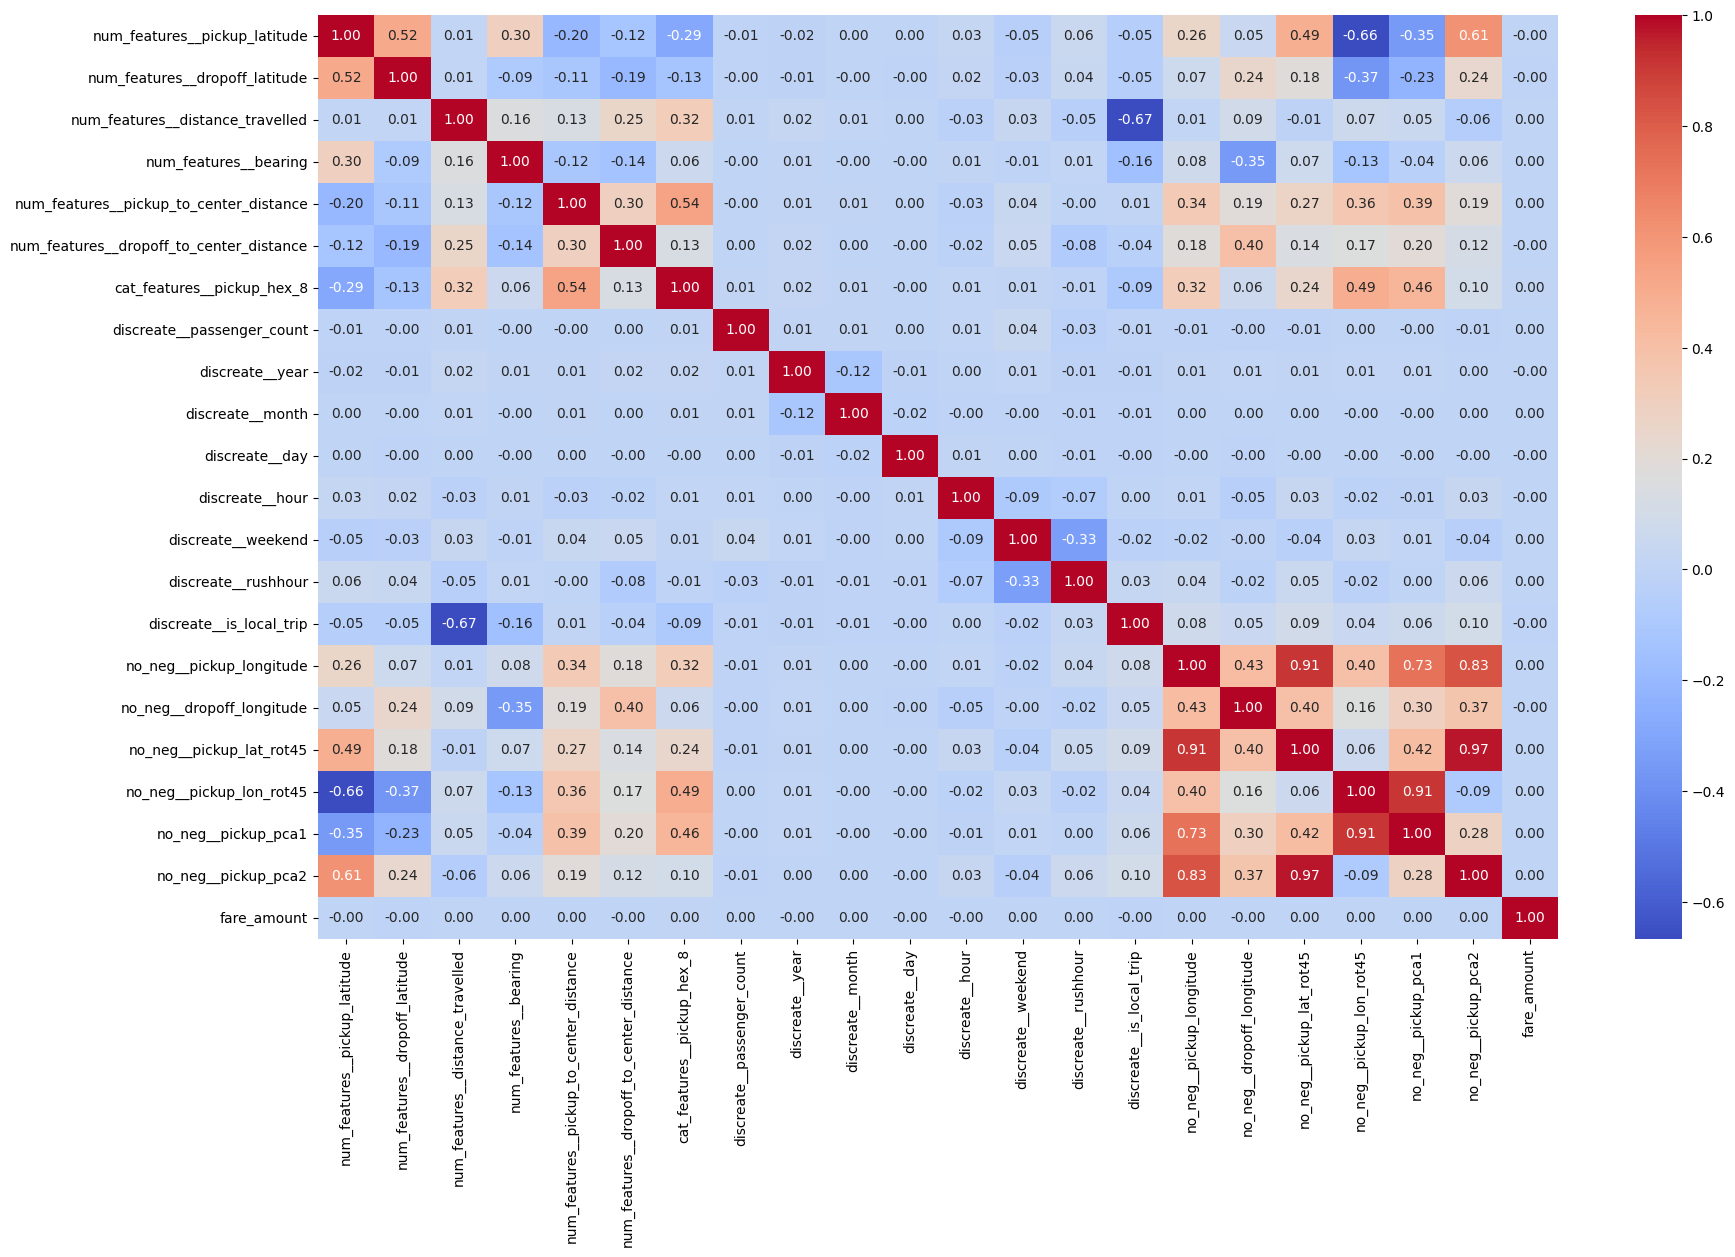

In [69]:
x_train_clean = pd.DataFrame(x_train_clean , columns= main_pipe.get_feature_names_out())
x_test_clean = pd.DataFrame(x_test_clean , columns= main_pipe.get_feature_names_out())
temp = pd.concat([pd.DataFrame(x_train_clean , columns= main_pipe.get_feature_names_out()),y_no_skew] , axis=1)
temp_corr = temp.corr()
plt.figure(figsize=(20, 12))
sns.heatmap(temp_corr , annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

### multicolinearity : when two columns have high correlation between each other , we drop one of them to save computations !


In [70]:
x_train_clean = x_train_clean.drop(['no_neg__pickup_lon_rot45' , 'no_neg__pickup_lon_rot45'] , axis = 1)

In [71]:
x_test_clean = x_test_clean.drop(['no_neg__pickup_lon_rot45' , 'no_neg__pickup_lon_rot45'] , axis = 1)

In [73]:
grad = GradientBoostingRegressor(random_state=42)
rand = RandomForestRegressor(random_state=42 , n_jobs=-1)
dec = DecisionTreeRegressor(random_state=42)
lin = LinearRegression()
rid = Ridge()
las = Lasso()
regression = {}
regression['model']= ["GRAD_BOOST", "RAND_FORESR" , "DECISION_tree" ,"lineae_regression" ,"RIDGE" ,"LASSO"]
regression['MAE'] = []
regression['MSE'] = []
regression['RMSE'] = []
regression['R²'] = []

In [75]:
rid_las_params = {'alpha' :[0.001 , 0.01 ,0.1,1,10,100,1000]} # will be used for both ridge and lasso !

dec_params = {'max_depth' : [5 ,10 ,15],
              'min_samples_split' :[3,5,10],
              'min_samples_leaf' : [1, 2, 5, 10, 20, 50 ,100],}

rand_params= {'n_estimators' :[100, 250] ,
              'max_depth': [5, 10, 15],
              'min_samples_split': [50 ,100]}

grad_params = {'n_estimators': [100, 250],
               'learning_rate':[0.01 ,0.1],
               'max_depth':[7,8],
               'subsample':[0.8, 1]}

In [ ]:
grad_cv = GridSearchCV(grad, grad_params, cv=3, scoring='neg_mean_squared_error', n_jobs=-1 , verbose = 2)
grad_cv.fit(x_train_clean,y_no_skew)

Fitting 3 folds for each of 16 candidates, totalling 48 fits


In [ ]:
rand_cv = GridSearchCV(rand, rand_params, cv=3, scoring='neg_mean_squared_error', n_jobs=-1 , verbose = 2)
rand_cv.fit(x_train_clean,y_no_skew)

In [ ]:
dec_cv = GridSearchCV(dec, dec_params, cv=3, scoring='neg_mean_squared_error', n_jobs=-1 , verbose=2)
dec_cv.fit(x_train_clean,y_no_skew)

In [ ]:
lin.fit(x_train_clean,y_no_skew)

In [ ]:
rid_cv = GridSearchCV(rid, rid_las_params, cv=3, scoring='neg_mean_squared_error', n_jobs=-1 , verbose=2)
rid_cv.fit(x_train_clean,y_no_skew)

In [ ]:
las_cv = GridSearchCV(las,rid_las_params,cv =3 ,scoring='neg_mean_squared_error',n_jobs=-1,verbose=2)
las_cv.fit(x_train_clean,y_no_skew)

In [ ]:
models = [grad_cv,rand_cv,dec_cv,lin,rid_cv,las_cv]
pred={}
for mod in models:
    predicted = np.expm1(mod.predict(x_test_clean))
    regression['MAE'].append(mean_absolute_error(y_test,predicted))
    regression['MSE'].append(mean_squared_error(y_test,predicted))
    regression['RMSE'].append(root_mean_squared_error(y_test,predicted))
    regression['R²'].append(r2_score(y_test,predicted))
    pred[mod]=predicted

pd.DataFrame(regression)

### residual_ploting

In [ ]:
error = prediction - y_test
sns.scatterplot(x= prediction , y =error ,  )
plt.title("residual plotting ")
plt.xlabel("fitted ' predicted ' ")
plt.ylabel("error")
plt.axhline(y=0 , c  ='r' , linestyle = '--' , linewidth = 2 ,   label = 'perfect fit')
plt.legend()
plt.show()